# EDA + Modeling Drill — Flotation Plant Recovery
**Scenario:** A mineral-processing plant runs 3 flotation lines. Each row is one hour of operation.
**Goal of the business:** understand what drives `recovery_pct` (% of metal recovered) before modeling.

**Rules:** fill every `____`. Each blank is one expression/name/argument. Hints are in comments.
Timebox: ~60 min. The dataset has **~10 planted problems** — find them all.

| Column | Meaning |
|---|---|
| timestamp | hourly reading |
| line_id | flotation line L1/L2/L3 |
| shift | Day/Night |
| ore_type | oxide / sulfide / mixed |
| ore_grade_pct | metal % in feed ore |
| feed_rate_tph | tonnes per hour |
| reagent_dose_gpt | collector dose, g/t |
| ph | slurry pH |
| temperature_c | slurry temp |
| particle_size_p80_um | grind size P80, microns |
| air_flow_m3min | flotation air |
| recovery_pct | **TARGET** |
| lab_assay_recovery_pct | lab-assayed recovery, reported next day |
| plant_id | plant code |

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
TARGET = "recovery_pct"
df_raw = pd.read_csv("../data/flotation_plant.csv")
df = df_raw.copy()          # never mutate the raw frame

## 1. First look — shape, dtypes, memory

In [2]:
print(df.shape)                 # (rows, cols) — attribute, no ()
df.head(5)

(2025, 14)


,timestamp,line_id,shift,ore_type,ore_grade_pct,feed_rate_tph,reagent_dose_gpt,ph,temperature_c,particle_size_p80_um,air_flow_m3min,recovery_pct,lab_assay_recovery_pct,plant_id
0,2026-01-01 00:00:00,L3,Night,mixed,1.980,328.7,35.97,9.01,24.7,177.1,13.64,58.69,60.30,PLANT_A
1,2026-01-01 01:00:00,L2,Night,sulfide,1.752,354.7,24.71,9.40,24.7,NaN,13.84,65.08,65.72,PLANT_A
2,2026-01-01 02:00:00,L3,Night,mixed,3.176,365.0,49.76,9.35,22.7,126.0,13.93,69.28,69.59,PLANT_A
3,2026-01-01 03:00:00,L2,Night,sulfide,3.711,308.1,42.91,9.22,25.0,140.8,13.04,72.57,72.92,PLANT_A
4,2026-01-01 04:00:00,L1,day,oxide,2.262,323.0,43.70,9.60,22.0,111.5,12.00,61.75,62.85,PLANT_A


In [4]:
df.info()                       # dtypes + non-null counts in one call
# Q: which column that should be numeric is 'object'? Which date column is 'object'?

<class 'pandas.DataFrame'>
RangeIndex: 2025 entries, 0 to 2024
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               2025 non-null   str    
 1   line_id                 2025 non-null   str    
 2   shift                   2025 non-null   str    
 3   ore_type                2025 non-null   str    
 4   ore_grade_pct           2025 non-null   float64
 5   feed_rate_tph           2025 non-null   str    
 6   reagent_dose_gpt        1944 non-null   float64
 7   ph                      1964 non-null   float64
 8   temperature_c           2025 non-null   float64
 9   particle_size_p80_um    1904 non-null   float64
 10  air_flow_m3min          2004 non-null   float64
 11  recovery_pct            2005 non-null   float64
 12  lab_assay_recovery_pct  2025 non-null   float64
 13  plant_id                2025 non-null   str    
dtypes: float64(8), str(6)
memory usage: 221.6 KB


In [5]:
df.describe(include="all").T   # transpose for readability
# Q: what looks impossible in min/max?

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,2025,2000,2026-01-10 15:00:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
line_id,2025,3,L1,792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shift,2025,4,Night,963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ore_type,2025,4,sulfide,975,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ore_grade_pct,2025.0,NaN,NaN,NaN,2.505455,0.49805,0.8,2.166,2.51,2.821,4.227
feed_rate_tph,2025,1092,310 tph,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reagent_dose_gpt,1944.0,NaN,NaN,NaN,44.840165,8.237604,16.77,39.5075,44.78,50.2,77.21
ph,1964.0,NaN,NaN,NaN,9.506899,0.482725,8.25,9.22,9.49,9.77,14.8
temperature_c,2025.0,NaN,NaN,NaN,28.679556,13.965538,21.1,26.3,28.0,29.6,326.0
particle_size_p80_um,1904.0,NaN,NaN,NaN,113.352416,28.579367,49.1,92.3,109.7,130.225,225.3


## 2. Data quality audit

### 2a. Duplicates

In [6]:
n_dup = df.duplicated().sum()
print(f"exact duplicate rows: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)

exact duplicate rows: 25


### 2b. Fix dtypes

In [7]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

# feed_rate_tph is a string. Find values that are NOT parseable as numbers
bad = pd.to_numeric(df["feed_rate_tph"], errors='coerce').isna() & df["feed_rate_tph"].notna()
print(df.loc[bad, "feed_rate_tph"].unique())

<StringArray>
['310 tph']
Length: 1, dtype: str


In [9]:
# Strip the unit text, then convert
df["feed_rate_tph"] = (df["feed_rate_tph"]
                       .str.replace(" tph", "", regex=False)
                       .pipe(pd.to_numeric))
df["feed_rate_tph"].dtype

dtype('float64')

### 2c. Constant / zero-information columns

In [10]:
nunique = df.nunique()
const_cols = nunique[nunique <= 1].index.tolist()
print("constant columns:", const_cols)
df = df.drop(columns=const_cols)

constant columns: ['plant_id']


### 2d. Categorical consistency

In [11]:
cat_cols = df.select_dtypes(exclude=["number", "datetime"]).columns   # works on pandas 2 & 3
for c in cat_cols:
    print(c, df[c].unique())

line_id <StringArray>
['L3', 'L2', 'L1']
Length: 3, dtype: str
shift <StringArray>
['Night', 'day ', 'NIGHT', 'Day']
Length: 4, dtype: str
ore_type <StringArray>
['mixed', 'sulfide', 'oxide', 'Sulfide']
Length: 4, dtype: str


In [12]:
# normalize: strip whitespace + Title-case  ('day ' -> 'Day', 'NIGHT' -> 'Night')
for c in cat_cols:
    df[c] = df[c].str.strip().str.title()
df["ore_type"] = df["ore_type"].str.lower()   # keep ore_type lowercase
for c in cat_cols:
    print(c, df[c].value_counts().to_dict())

line_id {'L1': 789, 'L2': 687, 'L3': 524}
shift {'Night': 1002, 'Day': 998}
ore_type {'sulfide': 1010, 'oxide': 606, 'mixed': 384}


### 2e. Missing values — how much, and is it random?

In [13]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss[miss > 0].round(2)

particle_size_p80_um    6.00
reagent_dose_gpt        4.00
ph                      3.00
air_flow_m3min          1.05
recovery_pct            1.00
dtype: float64

In [14]:
df.columns

Index(['timestamp', 'line_id', 'shift', 'ore_type', 'ore_grade_pct',
       'feed_rate_tph', 'reagent_dose_gpt', 'ph', 'temperature_c',
       'particle_size_p80_um', 'air_flow_m3min', 'recovery_pct',
       'lab_assay_recovery_pct'],
      dtype='str')

In [15]:
# Is air_flow missingness random, or tied to a line / period?
df.groupby("line_id")["air_flow_m3min"].apply(lambda s: s.isna().sum())

line_id
L1     0
L2     0
L3    21
Name: air_flow_m3min, dtype: int64

In [16]:
# When did L3's air_flow go missing?
m = df["air_flow_m3min"].isna() & (df["line_id"] == "L3")
df.loc[m, "timestamp"].agg(["min", "max", "count"])
# Q: MCAR, MAR or MNAR? How would you impute (or not)?

min      2026-02-10 04:00:00
max      2026-02-14 00:00:00
count                     21
Name: timestamp, dtype: object

In [17]:
# Rows with missing TARGET can't be used for supervised learning -> drop them
print("missing target:", df[TARGET].isna().sum())
df = df.dropna(subset=[TARGET])

missing target: 20


### 2f. Impossible values & sentinels (domain checks)

In [18]:
# Sentinel error codes are often -999 / 9999. Check the min of every numeric col
num_cols = df.select_dtypes(include='number').columns.drop(TARGET)
df[num_cols].min()

ore_grade_pct               0.80
feed_rate_tph            -999.00
reagent_dose_gpt           16.77
ph                          8.25
temperature_c              21.10
particle_size_p80_um       49.10
air_flow_m3min              7.11
lab_assay_recovery_pct     45.40
dtype: float64

In [19]:
# Replace sentinel with NaN, and enforce physical ranges
df.loc[df["feed_rate_tph"] <= 0, "feed_rate_tph"] = np.nan
df.loc[~df["ph"].between(0, 14), "ph"] = np.nan
print((df["temperature_c"] > 60).sum(), "temps > 60C")   # plausible slurry temp < 60
df.loc[df["temperature_c"] > 60, "temperature_c"] = np.nan

6 temps > 60C


### 2g. Stuck sensor (same value repeated many hours)

In [20]:
# run-length of identical consecutive values
s = df["temperature_c"]
run_id = (s != s.shift()).cumsum()
run_len = s.groupby(run_id).transform('size')
stuck = run_len >= 10
print("stuck readings:", stuck.sum(), df.loc[stuck, "timestamp"].agg(["min", "max"]).tolist())
df.loc[stuck, "temperature_c"] = np.nan

stuck readings: 61 [Timestamp('2026-01-26 00:00:00'), Timestamp('2026-01-28 12:00:00')]


## 3. Univariate analysis

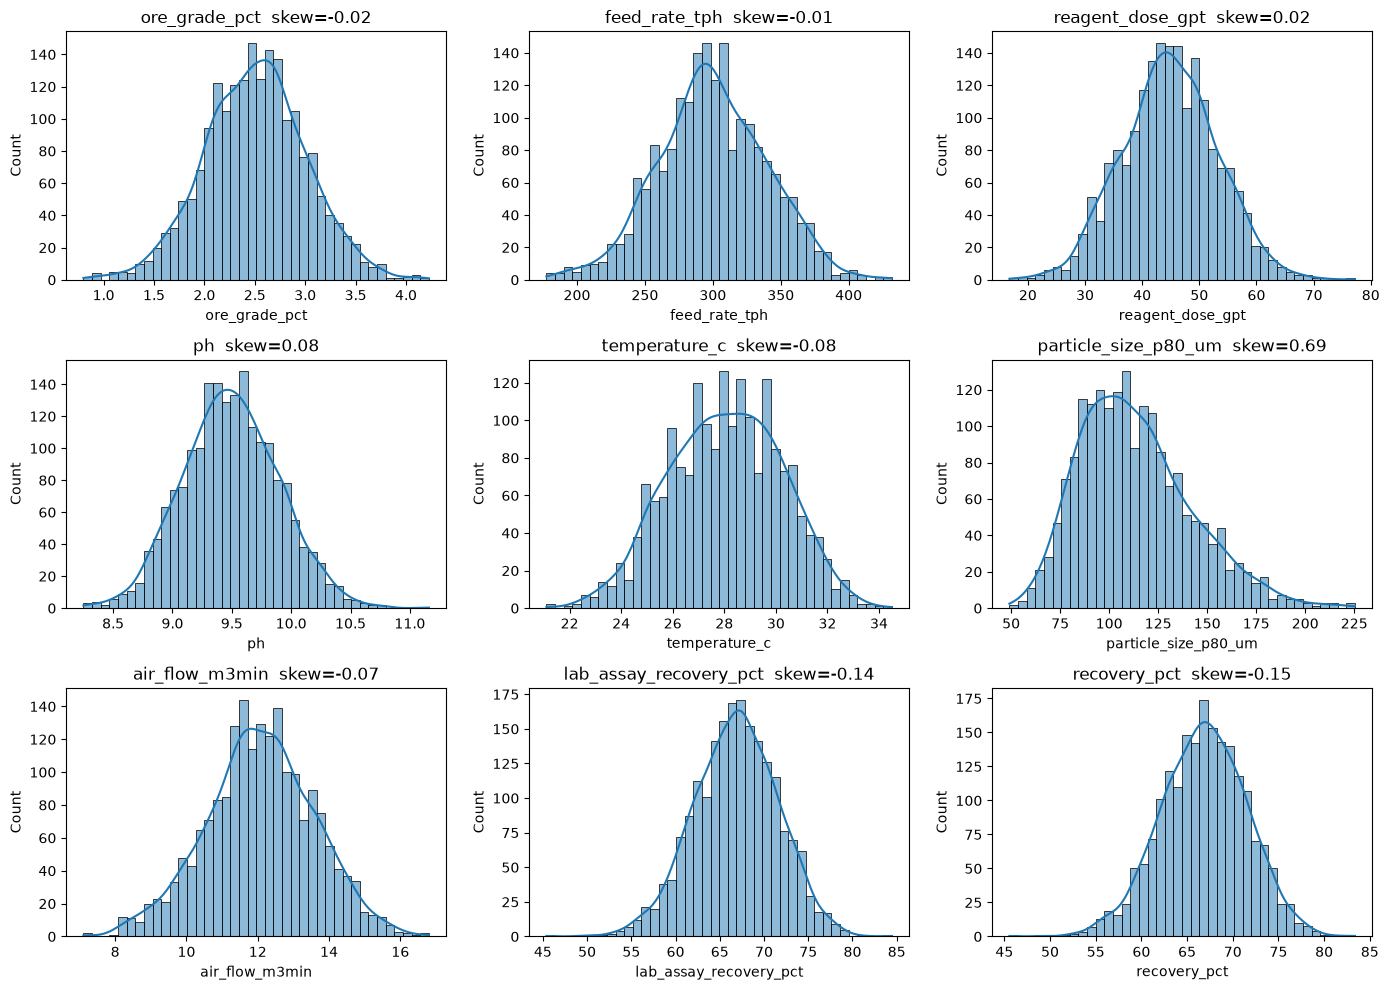

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, c in zip(axes.ravel(), list(num_cols) + [TARGET]):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, kde=True)
    ax.set_title(f"{c}  skew={df[c].skew():.2f}")
plt.tight_layout()

In [24]:
# IQR outlier count per numeric column
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
out = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
out.sort_values(ascending=False)
# Q: particle_size is right-skewed — what transform would you try?

particle_size_p80_um      27
ore_grade_pct             21
reagent_dose_gpt          21
feed_rate_tph             20
ph                        14
air_flow_m3min            14
lab_assay_recovery_pct    11
temperature_c              3
dtype: int64

## 4. Target vs. features

In [25]:
# Correlation with target — Pearson AND Spearman (catches monotonic non-linear)
corr = pd.DataFrame({
    "pearson":  df[num_cols].corrwith(df[TARGET]),
    "spearman": df[num_cols].corrwith(df[TARGET], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
corr.round(3)

,pearson,spearman
lab_assay_recovery_pct,0.992,0.991
ore_grade_pct,0.427,0.418
air_flow_m3min,0.269,0.274
particle_size_p80_um,-0.257,-0.242
feed_rate_tph,-0.249,-0.222
reagent_dose_gpt,0.243,0.246
temperature_c,0.030,0.039
ph,-0.021,-0.013


In [26]:
# 🚩 One feature correlates suspiciously well. Why?  (think: WHEN is it measured?)
LEAK = "lab_assay_recovery_pct"
num_cols = num_cols.drop(LEAK)

<Axes: title={'center': 'recovery vs pH decile'}, xlabel='ph_bin'>

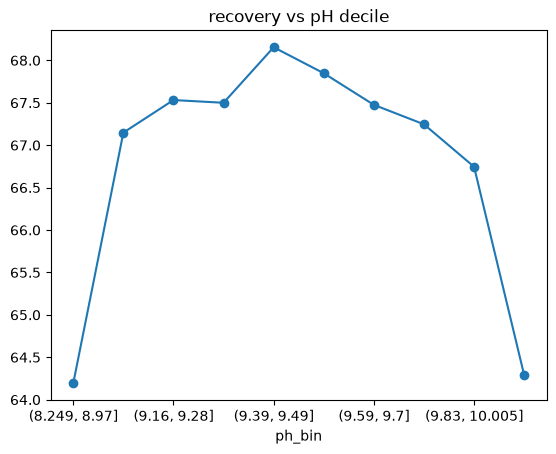

In [27]:
# pH has ~0 Pearson corr but matters — check the shape
df["ph_bin"] = pd.qcut(df["ph"], q=10)
df.groupby("ph_bin", observed=True)[TARGET].mean().plot(marker="o", title="recovery vs pH decile")
# Q: what shape? what feature would capture it for a linear model?

,mean,std,count
ore_type,,,
mixed,66.73,4.21,380
oxide,63.97,4.36,597
sulfide,68.53,4.24,1003


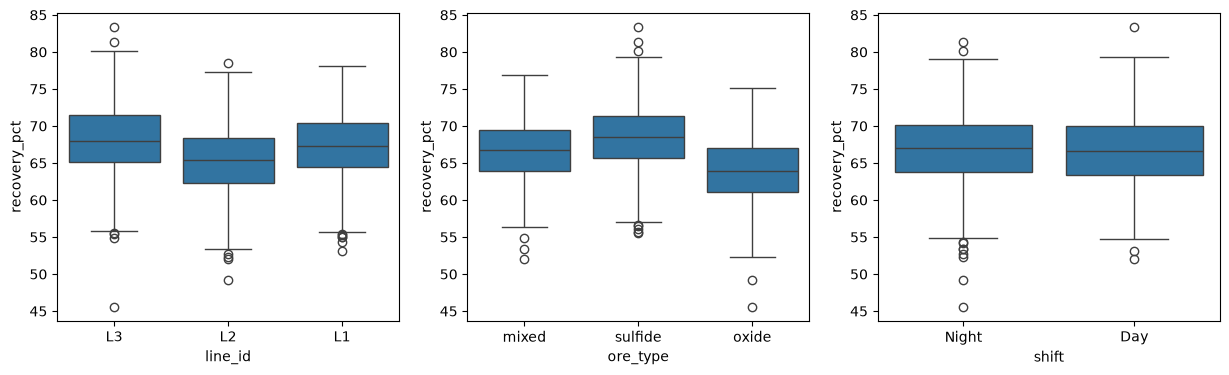

In [28]:
# Categorical drivers
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["line_id", "ore_type", "shift"]):
    sns.boxplot(data=df, x=c, y=TARGET, ax=ax)
df.groupby("ore_type")[TARGET].agg(["mean", "std", "count"]).round(2)

<Axes: >

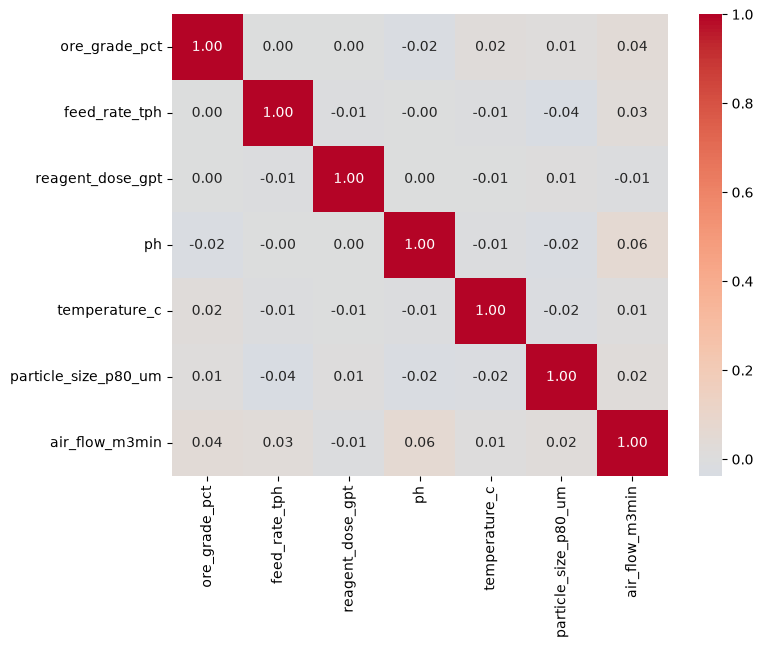

In [29]:
# Multicollinearity check among features
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

## 5. Time structure (matters for the CV split later!)

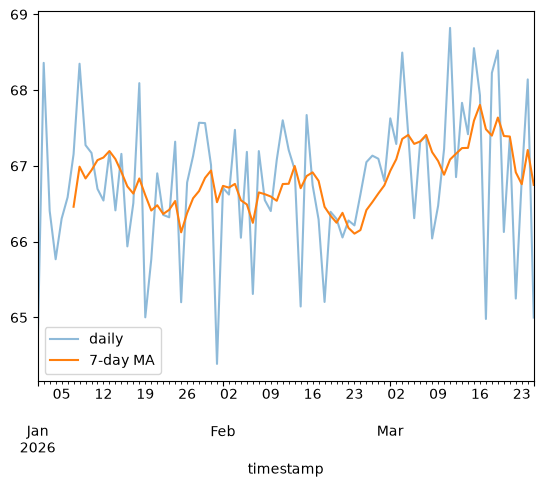

In [30]:
ts = df.set_index("timestamp").sort_index()
daily = ts[TARGET].resample("D").mean()
ax = daily.plot(alpha=0.5, label="daily")
daily.rolling(7).mean().plot(ax=ax, label="7-day MA")
ax.legend()

<Axes: title={'center': 'weekly recovery by line'}, xlabel='timestamp'>

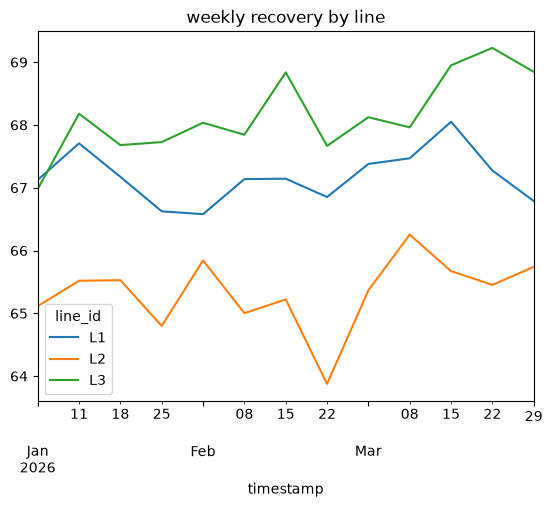

In [32]:
# Recovery by line over time — is any line drifting?
ts.groupby("line_id")[TARGET].resample("W").mean().unstack(0).plot(title="weekly recovery by line")
# Q: given hourly time series data, would you use random KFold? What instead?

## 6. EDA summary — write it like you'd say it to the interviewer
Fill in 5–7 bullets:
1. Data quality issues found & fix applied:
2. Leakage:
3. Strongest drivers:
4. Non-linear effects:
5. Missingness pattern & imputation plan:
6. Validation strategy implication:
7. Next step (baseline model):

---
# PART 2 — Modeling
**Goal:** a defensible baseline → simple model → strong general-purpose model, validated the right way.
Uses the cleaned `df` from Part 1 (run Part 1 first). Timebox: ~45 min.

## 7. Setup — features, target, time-ordered split

In [34]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

df = df.sort_values("timestamp").reset_index(drop=True)   # time order BEFORE splitting

NUM = ["ore_grade_pct", "feed_rate_tph", "reagent_dose_gpt", "ph", "temperature_c",
       "particle_size_p80_um", "air_flow_m3min"]
CAT = ["line_id", "shift", "ore_type"]
# NOT included: timestamp (id), ph_bin (EDA helper), ____ (leakage!)

X, y = df[NUM + CAT], df[TARGET]

In [37]:
# Hold out the LAST 20% of time as test — never shuffle a time series
cut = int(len(df) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]
print(df["timestamp"].iloc[cut - 1], "→", df["timestamp"].iloc[cut])
print(X_train.shape, X_test.shape)

2026-03-08 15:00:00 → 2026-03-08 16:00:00
(1584, 10) (396, 10)


In [38]:
X_train

,ore_grade_pct,feed_rate_tph,reagent_dose_gpt,ph,temperature_c,particle_size_p80_um,air_flow_m3min,line_id,shift,ore_type
0,1.980,328.7,35.97,9.01,24.7,177.1,13.64,L3,Night,mixed
1,1.752,354.7,24.71,9.40,24.7,NaN,13.84,L2,Night,sulfide
2,3.176,365.0,49.76,9.35,22.7,126.0,13.93,L3,Night,mixed
3,3.711,308.1,42.91,9.22,25.0,140.8,13.04,L2,Night,sulfide
4,2.262,323.0,43.70,9.60,22.0,111.5,12.00,L1,Day,oxide
...,...,...,...,...,...,...,...,...,...,...
1579,2.129,297.8,59.61,9.17,29.8,139.1,12.76,L2,Day,mixed
1580,2.537,309.2,44.92,9.65,29.4,NaN,9.11,L1,Day,mixed
1581,2.027,270.9,52.47,9.48,32.1,214.8,12.05,L1,Day,mixed
1582,2.243,226.5,42.72,10.24,28.5,149.2,11.23,L3,Day,mixed


In [39]:
def evaluate(name, model, results):
    """fit on train, score on test, store metrics"""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = {
        "MAE":  mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "R2":   r2_score(y_test, pred),
    }
    return pred

results = {}

## 8. Baseline 0 — predict the mean (the bar every model must beat)

In [40]:
dummy = DummyRegressor(strategy="mean")
_ = evaluate("0_mean_baseline", dummy, results)
pd.DataFrame(results).T.round(3)
# Q: what R2 should this have on test, roughly? Why might it be slightly negative?

,MAE,RMSE,R2
0_mean_baseline,3.978,4.992,-0.011


## 9. Model 1 — Ridge regression (linear, interpretable)

In [42]:
# Linear models need: imputation, scaling, one-hot encoding
num_lin = Pipeline([
    ("impute", SimpleImputer(strategy='median')),
    ("scale",  StandardScaler()),
])
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy='most_frequent')),
    ("ohe",    OneHotEncoder(handle_unknown='ignore')),   # safe if test has unseen category
])
pre_lin = ColumnTransformer([
    ("num", num_lin, NUM),
    ("cat", cat_pipe, CAT),
])
ridge = Pipeline([("pre", pre_lin), ("model", Ridge(alpha=1.0))])
pred_ridge = evaluate("1_ridge", ridge, results)
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
0_mean_baseline,3.978,4.992,-0.011
1_ridge,1.946,2.556,0.735


In [49]:
# Why the pipeline? Imputer medians & scaler means are learned on TRAIN only
# inside .fit() -> no test-set information leaks into preprocessing.
coefs = pd.Series(ridge.named_steps["model"].coef_,
                  index=ridge.named_steps["pre"].get_feature_names_out())
coefs.sort_values(key=abs, ascending=False).round(2)

cat__ore_type_oxide         -2.63
cat__ore_type_sulfide        2.24
num__ore_grade_pct           1.96
cat__line_id_L2             -1.75
cat__line_id_L3              1.58
num__particle_size_p80_um   -1.37
num__feed_rate_tph          -1.32
num__air_flow_m3min          1.30
num__reagent_dose_gpt        1.17
cat__ore_type_mixed          0.39
cat__line_id_L1              0.17
num__temperature_c          -0.06
cat__shift_Night             0.03
cat__shift_Day              -0.03
num__ph                      0.00
dtype: float64

## 10. Model 1b — Ridge + domain feature (pH is an inverted U, from EDA §4)

In [50]:
from sklearn.preprocessing import FunctionTransformer

def add_ph_sq(X):
    X = X.copy()
    X["ph_dev_sq"] = (X["ph"] - 9.5) ** 2   # distance from the optimum, squared
    return X

ridge_fe = Pipeline([
    ("fe",  FunctionTransformer(add_ph_sq)),
    ("pre", ColumnTransformer([("num", num_lin, NUM + ['ph_dev_sq']), ("cat", cat_pipe, CAT)])),
    ("model", Ridge(alpha=1.0)),
])
pred_ridge_fe = evaluate("1b_ridge_ph_sq", ridge_fe, results)
pd.DataFrame(results).T.round(3)
# Q: how much did ONE EDA-driven feature improve MAE?

,MAE,RMSE,R2
0_mean_baseline,3.978,4.992,-0.011
1_ridge,1.946,2.556,0.735
1b_ridge_ph_sq,1.638,2.060,0.828


## 11. Model 2 — Gradient-boosted trees (strong general-purpose baseline)

In [51]:
# HistGradientBoosting (sklearn's LightGBM-style model):
#  - handles NaN natively -> no imputer needed
#  - no scaling needed (trees split on thresholds)
#  - captures non-linearity (pH U-shape) + interactions automatically
pre_tree = ColumnTransformer([
    ("num", "passthrough", NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])
hgb = Pipeline([
    ("pre", pre_tree),
    ("model", HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_depth=None,
        min_samples_leaf=20, l2_regularization=1.0, random_state=42)),
])
pred_hgb = evaluate("2_hist_gbm", hgb, results)
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
0_mean_baseline,3.978,4.992,-0.011
1_ridge,1.946,2.556,0.735
1b_ridge_ph_sq,1.638,2.060,0.828
2_hist_gbm,1.907,2.514,0.744


## 12. Time-series cross-validation (is the test score stable or lucky?)

In [52]:
tscv = TimeSeriesSplit(n_splits=5)   # expanding window: train on past, validate on next block
cv_rows = {}
for name, model in [("ridge_ph_sq", ridge_fe), ("hist_gbm", hgb)]:
    cv = cross_validate(model, X_train, y_train, cv=tscv,
                        scoring=["neg_mean_absolute_error", "r2"])
    mae = -cv["test_neg_mean_absolute_error"]        # sklearn returns NEGATIVE errors
    cv_rows[name] = {"MAE_mean": mae.mean(), "MAE_std": mae.mean(), "R2_mean": cv["test_r2"].mean()}
pd.DataFrame(cv_rows).T.round(3)
# Q: why not KFold(shuffle=True)? What would happen to the scores?

,MAE_mean,MAE_std,R2_mean
ridge_ph_sq,1.758,1.758,0.776
hist_gbm,2.080,2.080,0.683


## 13. Leakage demo — what happens if you keep the leaky column?

In [53]:
X_leak = df[NUM + CAT + [LEAK]]
leak_model = Pipeline([
    ("pre", ColumnTransformer([("num", "passthrough", NUM + [LEAK]),
                               ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])),
    ("model", HistGradientBoostingRegressor(random_state=42)),
])
leak_model.fit(X_leak.iloc[:cut], y_train)
print("R2 WITH leak:", round(r2_score(y_test, leak_model.predict(X_leak.iloc[cut:])), 3))
# Q: how would you explain to a plant manager why this 'great' model is useless?

R2 WITH leak: 0.971


## 14. Diagnose the best model

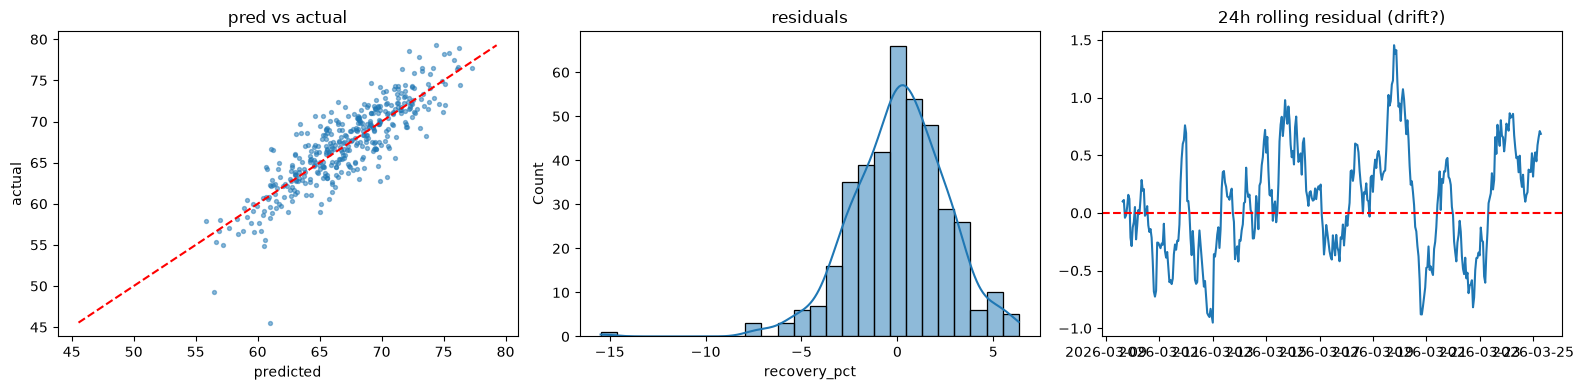

In [54]:
resid = y_test - pred_hgb
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(pred_hgb, y_test, s=8, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--"); axes[0].set(xlabel="predicted", ylabel="actual", title="pred vs actual")
sns.histplot(resid, kde=True, ax=axes[1]); axes[1].set_title("residuals")
axes[2].plot(df["timestamp"].iloc[cut:], resid.rolling(24).mean())
axes[2].axhline(0, color="r", ls="--"); axes[2].set_title("24h rolling residual (drift?)")
plt.tight_layout()

In [55]:
# Error by segment — does the model fail for a specific line / ore type?
seg = X_test.assign(abs_err=resid.abs())
seg.groupby("ore_type")["abs_err"].mean().round(3), seg.groupby("line_id")["abs_err"].mean().round(3)

(ore_type
 mixed      2.202
 oxide      1.782
 sulfide    1.883
 Name: abs_err, dtype: float64,
 line_id
 L1    1.721
 L2    1.972
 L3    2.081
 Name: abs_err, dtype: float64)

<Axes: title={'center': 'permutation importance (MAE increase)'}>

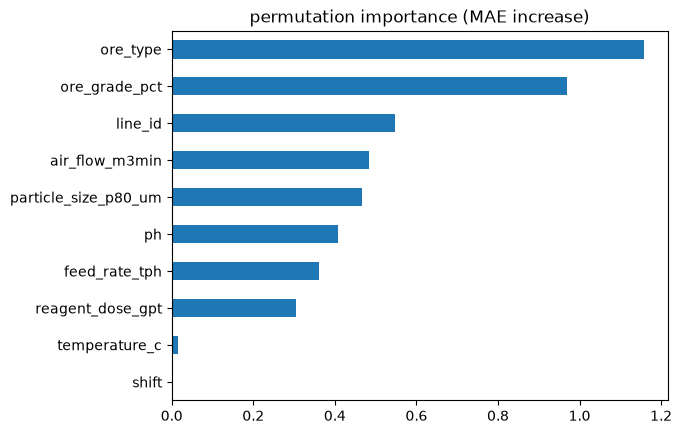

In [57]:
# Permutation importance on TEST (model-agnostic, works through the pipeline)
pi = permutation_importance(hgb, X_test, y_test, n_repeats=10, random_state=42,
                            scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(title="permutation importance (MAE increase)")
# Q: does this ranking agree with your EDA correlations? Where does pH land now, and why?

## 15. Final comparison

In [61]:
summary = pd.DataFrame(results).T.round(3)
summary["MAE_vs_baseline_%"] = (1 - summary["MAE"] / summary.loc['0_mean_baseline', "MAE"]) * 100
summary.sort_values("MAE")


,MAE,RMSE,R2,MAE_vs_baseline_%
1b_ridge_ph_sq,1.638,2.060,0.828,58.823529
2_hist_gbm,1.907,2.514,0.744,52.061337
1_ridge,1.946,2.556,0.735,51.080945
0_mean_baseline,3.978,4.992,-0.011,0.000000


## 16. Modeling summary — say it like the interviewer is listening
1. Validation design & why:
2. Baseline → final model, MAE improvement (%):
3. Did feature engineering or model choice matter more?
4. Top drivers (and how they match EDA):
5. Where the model is weakest:
6. Risks before deployment (drift, sensor outages, leakage):
7. If I had another hour, I would: